# Figure 3 · Conditional diffusion architecture

Implementation-verified vector diagram of the current full diffusion run.
Training, the shared conditional U-Net, and NISP-conditioned generation are
separate panels. This notebook reads source/provenance files only: it never
imports a model, loads checkpoints, launches inference, or uses a GPU.

The colored conditioning paths terminate in the residual-block inset, which
is used twice at every encoder, bottleneck, and decoder stage. No figure title.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v04'

In [2]:
FIGSIZE = (7.2, 5.6)
source_paths = [ROOT / 'code/diffusion_corrected.py', ROOT / 'code/diffusion/model_sr3.py',
                ROOT / 'code/train_diffusion_full.py']
provenance = ROOT / 'runs/diffusion-full50-s20261016/provenance.json'
verified_sources(provenance, ['diffusion_corrected.py', 'diffusion/model_sr3.py', 'train_diffusion_full.py'])
print('Verified source hashes against the full diffusion run.')

Verified source hashes against the full diffusion run.


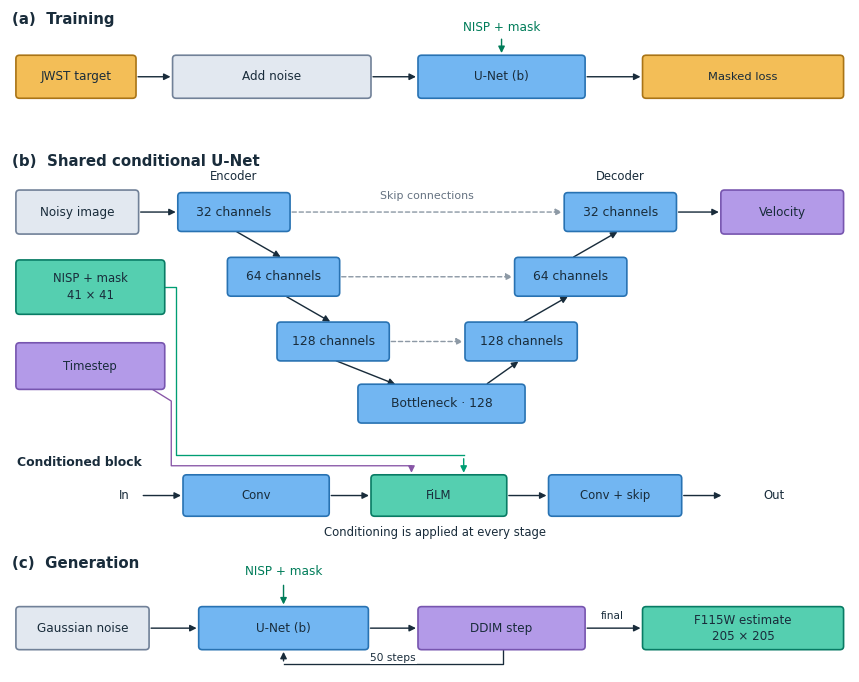

In [3]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Coordinates are local to each panel; all labels remain editable in SVG.
INK = '#192C3B'
BLUE = '#72B6F2'
TEAL = '#55CFB0'
PURPLE = '#B39AE8'
GOLD = '#F3BE57'
GRAY = '#E2E8F0'
EDGE_COLORS = {'#72B6F2':'#2872B2', '#55CFB0':'#087B64',
               '#B39AE8':'#7755AF', '#F3BE57':'#A97416', '#E2E8F0':'#718198'}
artists_for_review = []

def node(ax, x, y, w, h, text, fill=BLUE, size=7.2, edge=None):
    patch = FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.025,rounding_size=0.07',
                          facecolor=fill,edgecolor=edge or EDGE_COLORS[fill],linewidth=1.0,zorder=3)
    ax.add_patch(patch)
    label = ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=size,
                    color=INK,linespacing=1.35,zorder=4)
    artists_for_review.append((patch,label))
    return patch

def link(ax, start, end, color=INK, dashed=False, bend=0, head=True):
    patch = FancyArrowPatch(start,end,arrowstyle='-|>' if head else '-',
        mutation_scale=8,linewidth=.85,color=color,
        linestyle=(0,(3,2)) if dashed else '-',connectionstyle=f'arc3,rad={bend}',
        shrinkA=2,shrinkB=2,zorder=2)
    ax.add_patch(patch)

fig = plt.figure(figsize=FIGSIZE)
gs = fig.add_gridspec(3,1,height_ratios=[1.15,4.15,1.15],hspace=.12,
                      left=.018,right=.985,top=.985,bottom=.015)
train,net,sample = [fig.add_subplot(gs[i]) for i in range(3)]
for ax in [train,net,sample]:
    ax.axis('off'); ax.set_xlim(0,16)
train.set_ylim(0,2.25)
net.set_ylim(0,7.5)
sample.set_ylim(0,2.25)

# (a) Both prediction and reference quantities enter the training objective.
train.text(0,2.13,'(a)  Training',fontsize=9,fontweight='semibold',color=INK)
node(train,.1,.6,2.25,.85,'JWST target',GOLD)
node(train,3.1,.6,3.75,.85,
     'Add noise',GRAY)
node(train,7.8,.6,3.15,.85,'U-Net (b)',BLUE)
node(train,12.1,.6,3.8,.85,
     'Masked loss',GOLD,size=6.9)
for start,end in [((2.35,1.025),(3.1,1.025)),((6.85,1.025),(7.8,1.025)),
                  ((10.95,1.025),(12.1,1.025))]:link(train,start,end)
train.text(9.375,1.99,'NISP + mask',ha='center',fontsize=7.2,color='#007C59')
link(train,(9.375,1.88),(9.375,1.45),color='#007C59')

# (b) Feature dimensions are after the two residual blocks at each stage.
net.text(0,7.2,'(b)  Shared conditional U-Net',fontsize=9,fontweight='semibold',color=INK)
node(net,.1,5.9,2.3,.8,'Noisy image',GRAY)
enc=[(3.2,5.95),(4.15,4.7),(5.1,3.45)]
dec=[(10.6,5.95),(9.65,4.7),(8.7,3.45)]
W,H=2.1,.7
for positions in [enc,dec]:
    for (x,y),dimension in zip(positions,['32 channels','64 channels','128 channels']):
        node(net,x,y,W,H,dimension,BLUE,size=7.4)
node(net,6.65,2.25,3.15,.7,'Bottleneck · 128',BLUE,size=7.4)
node(net,13.6,5.9,2.3,.8,'Velocity',PURPLE)
link(net,(2.4,6.3),(3.2,6.3))
net.text(4.25,6.92,'Encoder',ha='center',fontsize=7,color=INK)
link(net,(12.7,6.3),(13.6,6.3))
net.text(11.65,6.92,'Decoder',ha='center',fontsize=7,color=INK)
for (x1,y1),(x2,y2) in zip(enc,enc[1:]):
    link(net,(x1+W/2,y1),(x2+W/2,y2+H))
link(net,(enc[-1][0]+W/2,enc[-1][1]),(7.4,2.95))
link(net,(9.05,2.95),(dec[-1][0]+W/2,dec[-1][1]))
for (x1,y1),(x2,y2) in zip(dec[::-1],dec[::-1][1:]):
    link(net,(x1+W/2,y1+H),(x2+W/2,y2))
for (x1,y1),(x2,y2) in zip(enc,dec):
    link(net,(x1+W,y1+H/2),(x2,y2+H/2),color='#8D99A5',dashed=True)
net.text(7.95,6.55,'Skip connections',ha='center',fontsize=6.6,color='#657281')

# Condition inputs connect to the modulation inside the shared block inset.
node(net,.1,4.35,2.8,1.0,'NISP + mask\n41 × 41',TEAL,size=7)
node(net,.1,2.9,2.8,.85,'Timestep',PURPLE,size=7)
# A local block inset avoids suggesting that conditioning reaches only one scale.
net.text(.1,1.4,'Conditioned block',fontsize=7.4,fontweight='semibold',color=INK)
node(net,3.3,.45,2.75,.75,'Conv',BLUE,size=7)
node(net,6.9,.45,2.55,.75,'FiLM',TEAL,size=7)
node(net,10.3,.45,2.5,.75,'Conv + skip',BLUE,size=7)
link(net,(2.45,.825),(3.3,.825))
link(net,(6.05,.825),(6.9,.825))
link(net,(9.45,.825),(10.3,.825))
link(net,(12.8,.825),(13.65,.825))
net.text(2.15,.825,'In',ha='center',va='center',fontsize=7,color=INK)
net.text(14.6,.825,'Out',ha='center',va='center',fontsize=7,color=INK)
# Routed paths around the architecture, to the inset's modulation inputs.
net.plot([2.9,3.15,3.15,8.65],[4.85,4.85,1.6,1.6],color='#009E73',lw=.8,zorder=1)
link(net,(8.65,1.6),(8.65,1.2),color='#009E73')
net.plot([2.65,3.05,3.05,7.65],[2.9,2.65,1.4,1.4],
         color='#8856A7',lw=.8,zorder=1)
link(net,(7.65,1.4),(7.65,1.2),color='#8856A7')
net.text(8.1,.05,'Conditioning is applied at every stage',ha='center',fontsize=7,color=INK)

# (c) The same learned U-Net is called at every sampling transition.
sample.text(0,2.13,'(c)  Generation',fontsize=9,fontweight='semibold',color=INK)
node(sample,.1,.45,2.5,.85,'Gaussian noise',GRAY)
node(sample,3.6,.45,3.2,.85,'U-Net (b)',BLUE)
node(sample,7.8,.45,3.15,.85,'DDIM step',PURPLE)
node(sample,12.1,.45,3.8,.85,'F115W estimate\n205 × 205',TEAL,size=7.1)
for start,end in [((2.6,.875),(3.6,.875)),((6.8,.875),(7.8,.875)),
                  ((10.95,.875),(12.1,.875))]:link(sample,start,end)
sample.text(5.2,1.98,'NISP + mask',ha='center',fontsize=7.2,color='#007C59')
link(sample,(5.2,1.84),(5.2,1.3),color='#007C59')
sample.plot([9.4,9.4,5.2],[.45,.12,.12],color=INK,lw=.8,zorder=1)
link(sample,(5.2,.12),(5.2,.45))
sample.text(7.3,.15,'50 steps',ha='center',va='bottom',fontsize=6.4,
            color=INK,bbox=dict(facecolor='white',edgecolor='none',pad=.5))
sample.text(11.5,1.07,'final',ha='center',fontsize=6.3,color=INK)
plt.show()


In [4]:
paths = export(fig, f'fig03_diffusion_architecture_{VERSION}', '03_diffusion_architecture.ipynb',
    [*source_paths, provenance],
    dict(figsize=FIGSIZE, display='simplified labels; channel counts only; equations in implementation notes', parameters=4910593, prediction='v', timesteps=1000,
         conditioning='NISP intensity and validity mask; FiLM in every residual block',
         encoder_shapes=['208x208x32','104x104x64','52x52x128'],
         bottleneck_shape='26x26x128', residual_blocks=14,
         timestep_embedding=256, inference_steps=50, ddim_eta=0,
         loss='valid-pixel velocity MSE + 0.1 reconstructed-target L1 in model coordinates',
         padding='reflect 205 to 208; output cropped to 205',
         colors=dict(features=BLUE,condition=TEAL,time=PURPLE,target=GOLD,neutral=GRAY,ink=INK,borders=EDGE_COLORS)),
    status='Figure 3 review draft: source-verified training, architecture and generation')


Exported: fig03_diffusion_architecture_v04.pdf, fig03_diffusion_architecture_v04.svg, fig03_diffusion_architecture_v04.png


## Working caption

Diffusion model for reconstructing F115W images from NISP observations.
(a) Training uses JWST targets with added noise; errors are measured only over
valid target pixels. (b) The U-Net combines image features at several spatial
scales, with the number of feature maps indicated in each stage. The NISP image,
its validity mask, and the noise level guide the updates within each block
through learned rescalings and offsets (FiLM). (c) Starting from Gaussian noise,
50 successive updates produce a 205 × 205 F115W estimate. The prediction is
converted back to surface brightness before evaluation.

## Implementation notes

The simplified drawing groups normalization, activations, projections, padding,
and cropping into the adjacent network blocks. The complete settings remain
in the export provenance and below; simplification does not change the model.

- The U-Net has 4,910,593 parameters, with encoder/decoder feature sizes
  208² × 32, 104² × 64, and 52² × 128, and a 26² × 128 bottleneck.
  Reflection padding takes 205 to 208 pixels; the output is cropped back to 205.
- Each of the three encoder and decoder stages and the bottleneck has two
  residual blocks (14 total). Downsampling uses strided convolutions and
  upsampling uses transposed convolutions.
- NISP intensity is bilinearly upsampled; the input validity mask uses nearest
  neighbors. A learned conditioning pyramid follows the encoder and decoder.
- The 256-dimensional sinusoidal/MLP timestep embedding feeds all residual blocks.
- Each residual block applies GN → SiLU → convolution → GN → FiLM → SiLU →
  convolution, then adds the residual connection (with a projection if needed).
  FiLM applies `(1 + gamma_t + gamma_c) * normalized_features + beta_t + beta_c`.
- Both input and target use saved asinh coordinates. The training loss is masked
  velocity MSE + 0.1 reconstructed-target L1, evaluated in model coordinates.
  With `a = sqrt(alpha_bar)` and `b = sqrt(1-alpha_bar)`, training uses
  `x_t = a*x_0 + b*noise`, `v = a*noise - b*x_0`, and `x0_hat = a*x_t - b*v_hat`.
- Training samples 1,000 cosine-schedule timesteps with exactly zero terminal
  signal. Sampling uses 50 deterministic DDIM transitions, with no output clipping.
- Source hashes match the recorded full run. No model is constructed for this figure.
